# IRIS Dataset – Exploratory Data Analysis (EDA)

**Student:** Manya  
**Project:** Pandas – Data Cleaning Project  
**Dataset:** Iris (150 rows, 3 species) – basic EDA only, no machine learning  
**Tools:** Python, NumPy, Pandas, Matplotlib

---
## Questions answered in this notebook (in order)
- **Question 1:** How many records are there for each species?
- **Question 2:** What are the mean, median, minimum and maximum sepal length?
- **Question 3:** Which species has the highest average petal length and petal width?
- **Question 4:** What are the five flowers with the largest petal length?
- **Question 5:** Are any values missing or duplicated?
- **Question 6:** How do the average sepal and petal measurements compare across species?

Setup and basic inspection come first, then Questions 1 to 6 in order, then the two charts and the 3 observations.

## Setup: Import Libraries and Load the Dataset
Import NumPy, Pandas and Matplotlib, load the Iris dataset, rename the columns and map the species codes (0, 1, 2) to their names.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
df["species"] = df["species"].map({0: "setosa", 1: "versicolor", 2: "virginica"})

## Basic Inspection of the Data
View the first and last rows with `head()` and `tail()`, then check the size with `shape`, column types with `info()` and summary statistics with `describe()`.

In [ ]:
display(df.head())
display(df.tail())
print(df.shape)
df.info()
display(df.describe())

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


(150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## Question 1: Records per Species
**How many records are there for each species?**  
Use `value_counts()` on the species column.

In [ ]:
species_counts = df["species"].value_counts()
print(species_counts)

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## Question 2: Sepal Length Statistics (NumPy)
**What are the mean, median, minimum and maximum sepal length?**  
Convert the columns to NumPy arrays and calculate the statistics (petal length is included as well, since it is used later for the histogram).

In [ ]:
sepal_len = df["sepal_length"].to_numpy()
petal_len = df["petal_length"].to_numpy()
for name, arr in [("sepal_length", sepal_len), ("petal_length", petal_len)]:
    print(name, "| mean:", round(np.mean(arr), 3), "| median:", np.median(arr),
          "| min:", np.min(arr), "| max:", np.max(arr))

sepal_length | mean: 5.843 | median: 5.8 | min: 4.3 | max: 7.9
petal_length | mean: 3.758 | median: 4.35 | min: 1.0 | max: 6.9


## Question 3: Species with the Highest Average Petal Length and Width
**Which species has the highest average petal length and petal width?**  
Use `groupby()` to get the mean petal measurements for each species, then pick the highest with `idxmax()`.

In [ ]:
petal_means = df.groupby("species")[["petal_length", "petal_width"]].mean().round(3)
display(petal_means)
print("Highest petal length:", petal_means["petal_length"].idxmax())
print("Highest petal width:", petal_means["petal_width"].idxmax())

,petal_length,petal_width
species,,
setosa,1.462,0.246
versicolor,4.260,1.326
virginica,5.552,2.026


Highest petal length: virginica
Highest petal width: virginica


## Question 4: Five Flowers with the Largest Petal Length
**What are the five flowers with the largest petal length?**  
Sort by `petal_length` in descending order and take the top 5 with `head()`.

In [ ]:
display(df.sort_values("petal_length", ascending=False).head(5))

,sepal_length,sepal_width,petal_length,petal_width,species
118,7.7,2.6,6.9,2.3,virginica
117,7.7,3.8,6.7,2.2,virginica
122,7.7,2.8,6.7,2.0,virginica
105,7.6,3.0,6.6,2.1,virginica
131,7.9,3.8,6.4,2.0,virginica


## Question 5: Missing Values and Duplicates
**Are any values missing or duplicated?**  
Count missing values in each column and look for duplicate rows.

In [ ]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
display(df[df.duplicated(keep=False)])

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
Duplicates: 1


,sepal_length,sepal_width,petal_length,petal_width,species
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica


## Question 6: Compare Average Measurements Across Species
**How do the average sepal and petal measurements compare across species?**  
Use `groupby()` to get the mean of all four measurements for every species.

In [ ]:
display(df.groupby("species").mean().round(3))

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


## Chart 1: Species Count Bar Chart
A bar chart showing the number of records for each species.

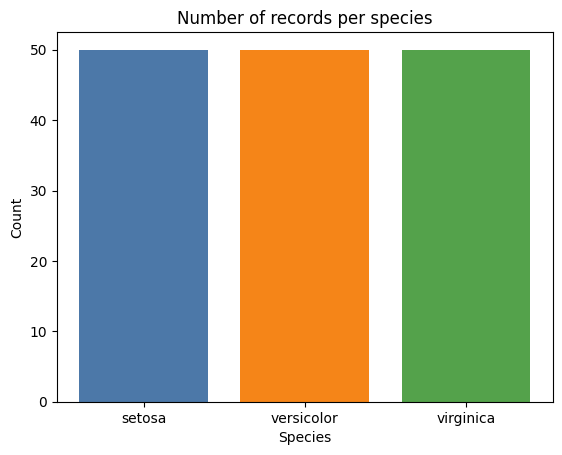

In [ ]:
plt.bar(species_counts.index, species_counts.values, color=["#4C78A8", "#F58518", "#54A24B"])
plt.title("Number of records per species")
plt.xlabel("Species"); plt.ylabel("Count")
plt.show()

## Chart 2: Petal Length Histogram
A histogram showing how petal length is distributed across all 150 flowers.

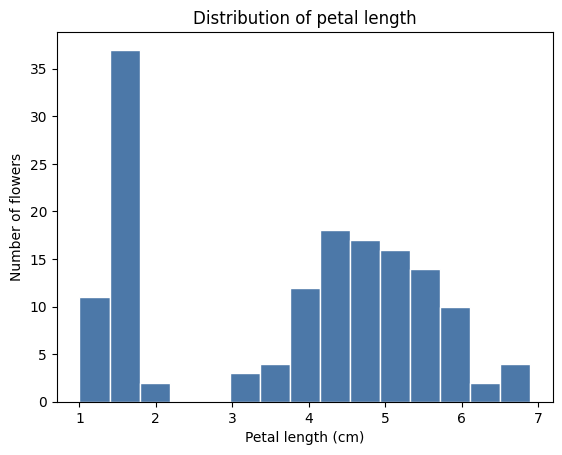

In [ ]:
plt.hist(petal_len, bins=15, color="#4C78A8", edgecolor="white")
plt.title("Distribution of petal length")
plt.xlabel("Petal length (cm)"); plt.ylabel("Number of flowers")
plt.show()

## Observations
1. **Balanced dataset:** There are 150 records with 50 flowers for each of the three species, and no missing values. Only one duplicate row exists (a virginica flower with identical measurements), which is a genuine repeat measurement and can be kept.
2. **Virginica has the largest petals:** Its average petal length (about 5.55 cm) and petal width (about 2.03 cm) are the highest, while setosa has the smallest (about 1.46 cm and 0.25 cm). Versicolor lies in between.
3. **Petal size separates species best:** Petal measurements differ much more between species than sepal measurements do. The petal length histogram shows a separate cluster for setosa, and all five longest petals (6.4 to 6.9 cm) belong to virginica.